In [144]:
from scripts.compiled import Problem 
import numpy as np 
import matplotlib.pyplot as plt 
from scripts.read_field import read_dir
from scripts.scientific import apply, colors 

from scripts.ansatz import DomainWallAnsatz, Ansatz

apply()

In [208]:
p = Problem(epsilon=0.3, beta=1, method='DOP853')
ans = p.probe_shooting(p.r, 0.2, 1000, 10)[0]

ansatz = Ansatz(theta = lambda r, p, problem: DomainWallAnsatz.theta(r, p[0], p[1]), theta_r = lambda r, p, problem: DomainWallAnsatz.theta_r(r, p[0], p[1]))
R, d = ansatz.minimize([1,1], p).x

exp = read_dir("./04-creation/skyrmion_system/drive-100-ansatz-compare")
exp_r = np.linspace(0, 10, exp.shape[2] // 2)
exp_theta = np.arccos(exp[5,exp.shape[1]//2,exp.shape[2]//2:,2])


(0.0, 4.0)

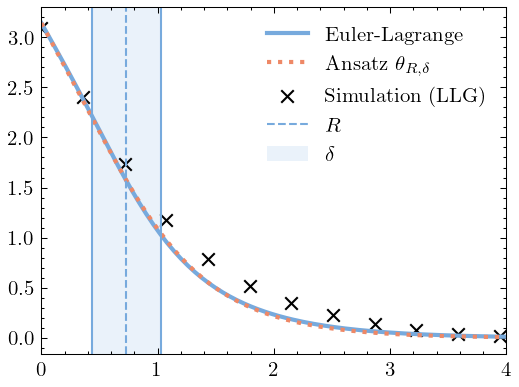

In [209]:
plt.figure(figsize=(4,3))
plt.plot(ans.r, ans.theta, linewidth=2, label='Euler-Lagrange')
plt.plot(ans.r, ansatz.theta(ans.r, [R,d] ,p), linewidth=2, linestyle=':', label='Ansatz $\\theta_{R,\\delta}$')
plt.scatter(exp_r[::10], exp_theta[::10], marker='x', color='k', label='Simulation (LLG)')
plt.axvline(R, label='$R$', linestyle='--')
plt.axvline(R-d /2)
plt.axvline(R+d /2)
plt.axvspan(
    R-d/2,
    R+d/2,
    zorder=0,
    label='$\\delta$',
    facecolor=(0.47, 0.67, 0.87, 0.15),
    clip_on=False,
    linewidth=2
)
plt.legend()
plt.xlim([0,4])